# Rainfall projections

Multi-model CMIP6 projections prepared by CSIRO on a common 1° Pacific grid. Every model's annual series is averaged over each EEZ and ocean region (cosine-of-latitude weights) and expressed as the change relative to its own 2015–2035 mean. For each indicator:

* **Trend map** — linear trend over 2015–2100 of the multi-model median change in each EEZ, one panel per scenario.
* **Warming-level map** — multi-model median change in each EEZ in the year `map_scenario` first reaches each global warming level.
* **Ocean-region box plots** — spread across models at each warming level for the four ocean regions, one figure per region.

```{glue:figure} pr_fig
:scale: 60%
:align: center
```

**Figure. Change in total rainfall relative to 2015–2035 in each Pacific EEZ at the global warming levels** (multi-model median, `map_scenario`).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ and ocean-region means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
sys.path.append("../../../../functions")
import projections as prj
import projections_regional as reg

### Configuration

Scenarios and global warming levels are the ones of the national projections ([`../../National/00_warming_levels.ipynb`](../../National/00_warming_levels.ipynb)). Maps of the change at warming levels use `map_scenario`; box plots show every scenario. Figures go to `outputs/figures/regional_pacific/PRJ_*` and tables to `outputs/tables/regional_pacific/PRJ_*`.

In [3]:
ssp_scenarios = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
map_scenario = "ssp370"
scenario_info = prj.load_warming_levels(ssp_scenarios)

eez = reg.load_eez()
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

## Total rainfall

Annual total rainfall (sum of monthly totals), change in %.

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP126,+1.5°C,2032,36,1.70,-7.85,16.23,-34.51,21.30
1,North Pacific Subtropical Gyre,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,North Pacific Subtropical Gyre,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,North Pacific Subtropical Gyre,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,36,6.05,-6.18,16.22,-33.90,25.18
...,...,...,...,...,...,...,...,...,...,...
59,South Pacific Subtropical Gyre,SSP370,+3.0°C,2075,36,-6.46,-17.24,4.11,-25.59,9.25
60,South Pacific Subtropical Gyre,SSP585,+1.5°C,2027,36,0.01,-6.30,5.32,-13.62,26.84
61,South Pacific Subtropical Gyre,SSP585,+2.0°C,2041,36,-1.33,-8.23,6.91,-21.24,13.84
62,South Pacific Subtropical Gyre,SSP585,+2.5°C,2053,36,-1.06,-16.23,5.97,-24.04,10.14


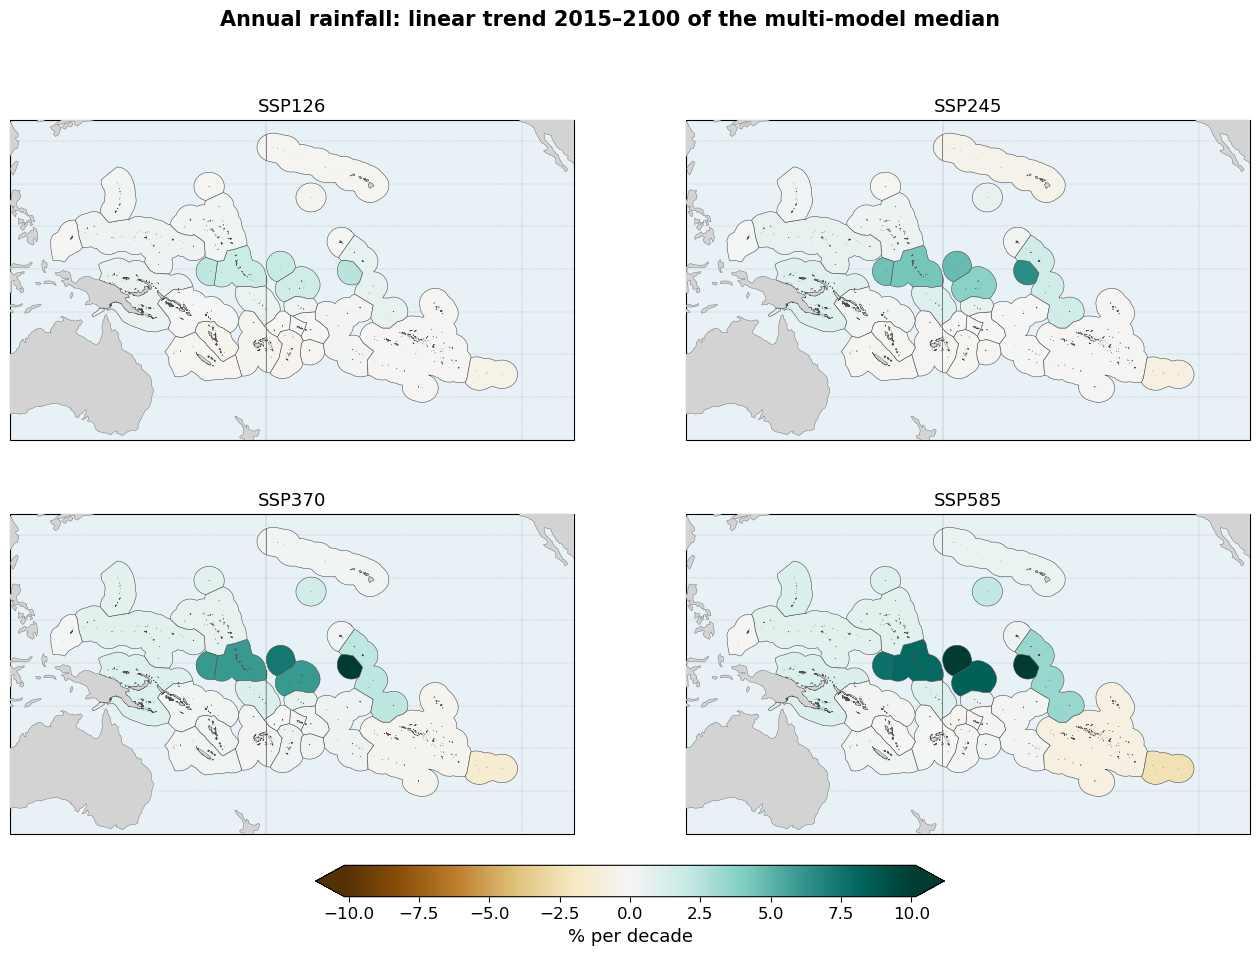

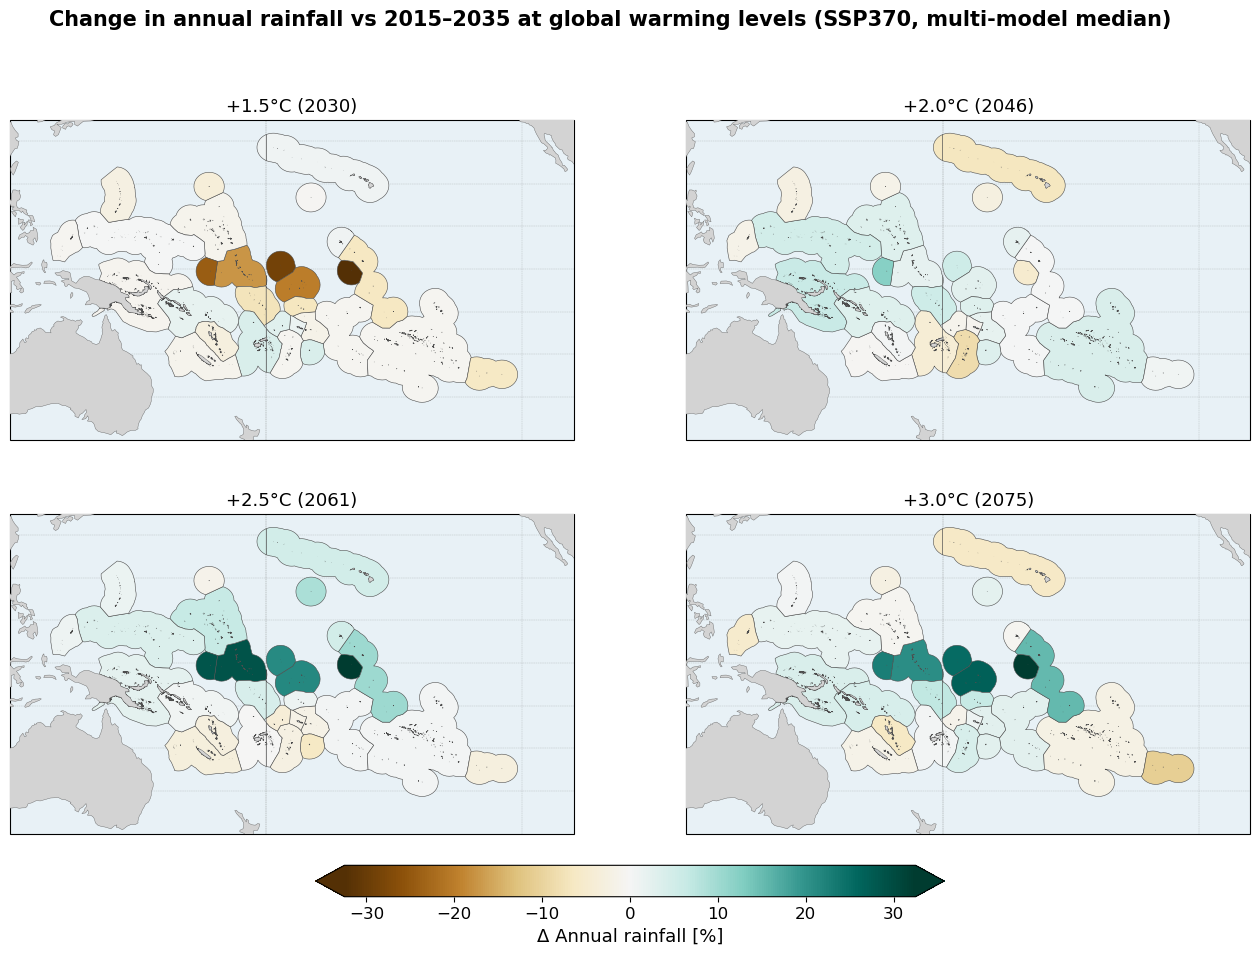

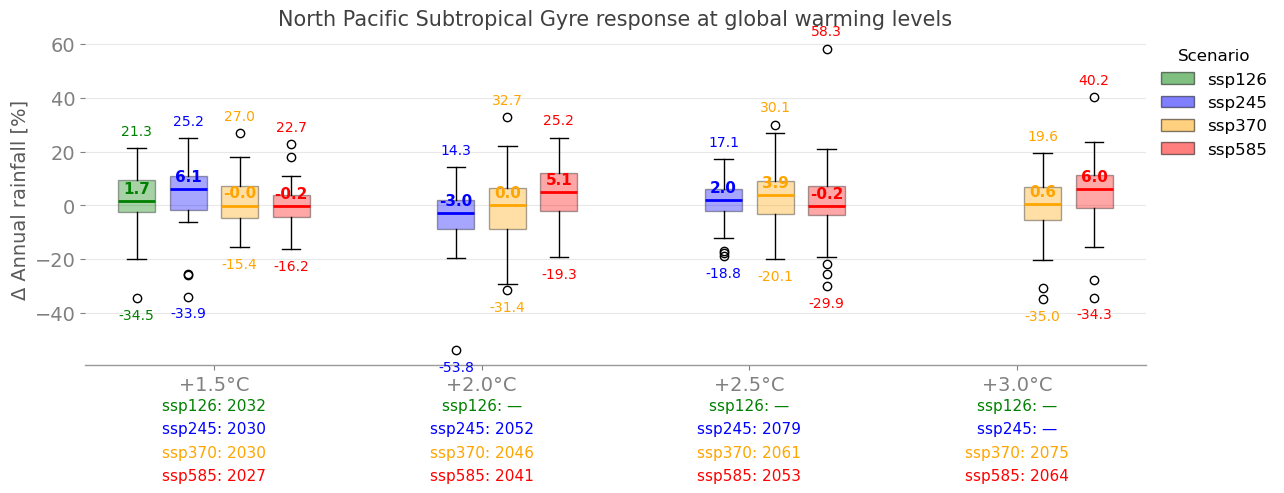

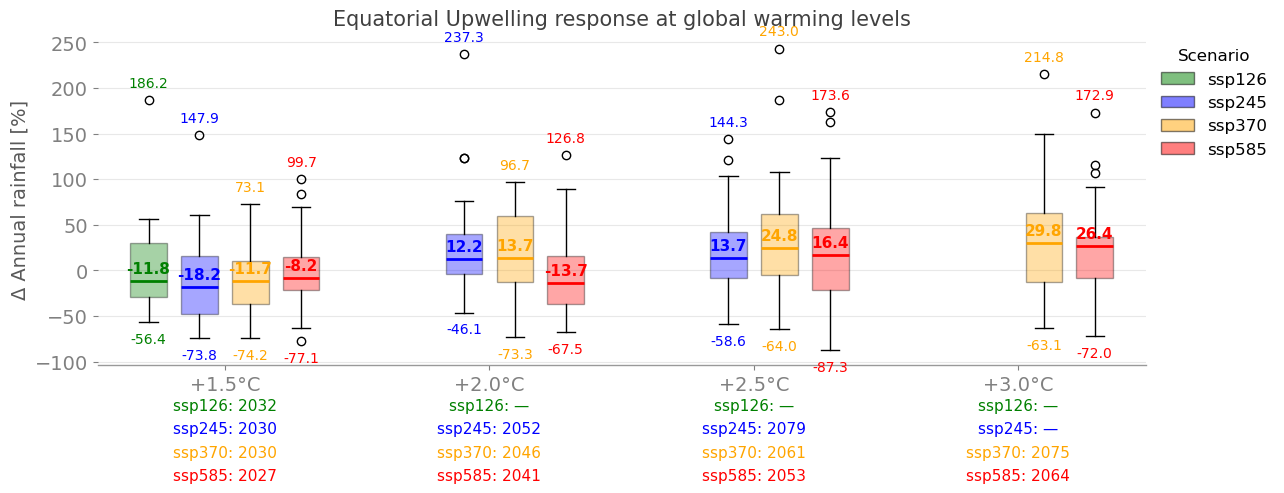

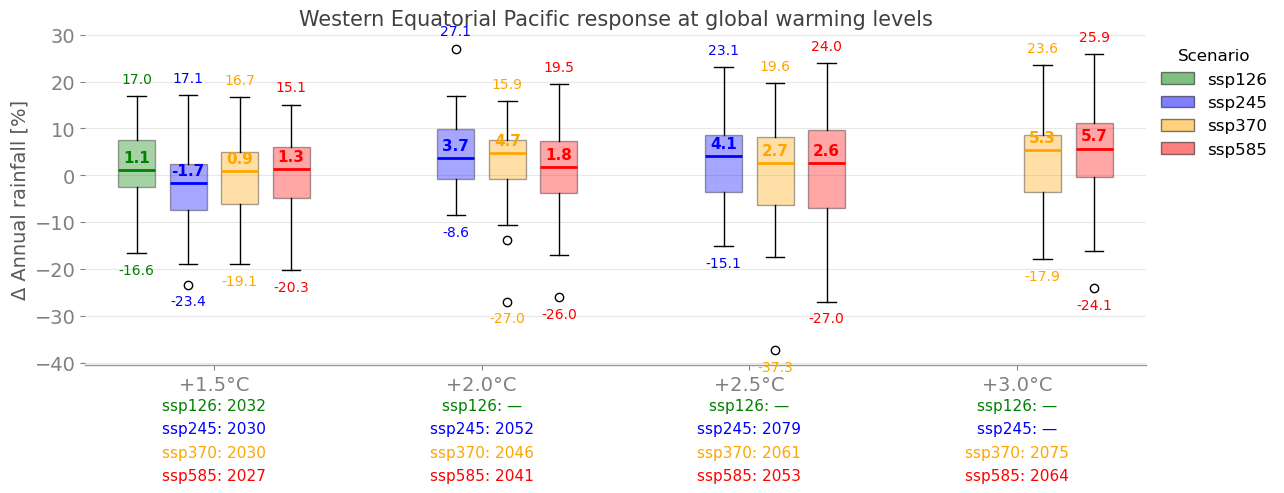

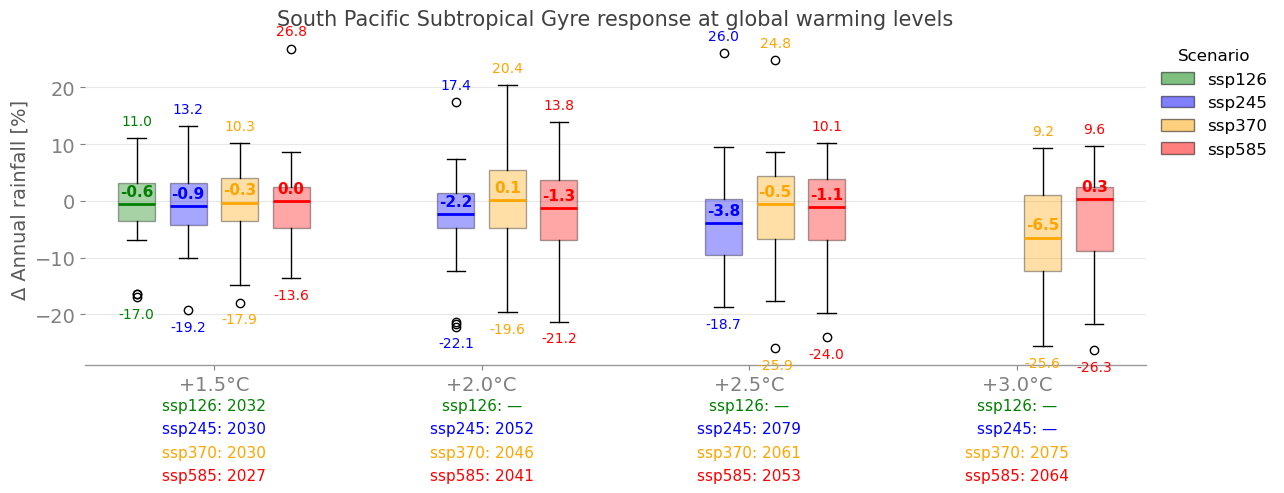

In [4]:
ds = reg.extract_regional_means("pr", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "pr", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
glue("pr_fig", figs["levels"], display=False)
tables["regions"]

## Dry days

Annual number of dry days.

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP126,+1.5°C,2032,30,-2.0,-12.2,4.8,-17.8,29.1
1,North Pacific Subtropical Gyre,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,North Pacific Subtropical Gyre,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,North Pacific Subtropical Gyre,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,30,-5.8,-16.9,8.1,-22.4,28.1
...,...,...,...,...,...,...,...,...,...,...
59,South Pacific Subtropical Gyre,SSP370,+3.0°C,2075,30,5.7,-2.6,19.0,-7.5,29.8
60,South Pacific Subtropical Gyre,SSP585,+1.5°C,2027,30,-0.1,-6.4,6.0,-15.3,13.9
61,South Pacific Subtropical Gyre,SSP585,+2.0°C,2041,30,0.8,-6.4,12.3,-14.5,20.5
62,South Pacific Subtropical Gyre,SSP585,+2.5°C,2053,30,3.5,-3.4,15.6,-19.6,25.8


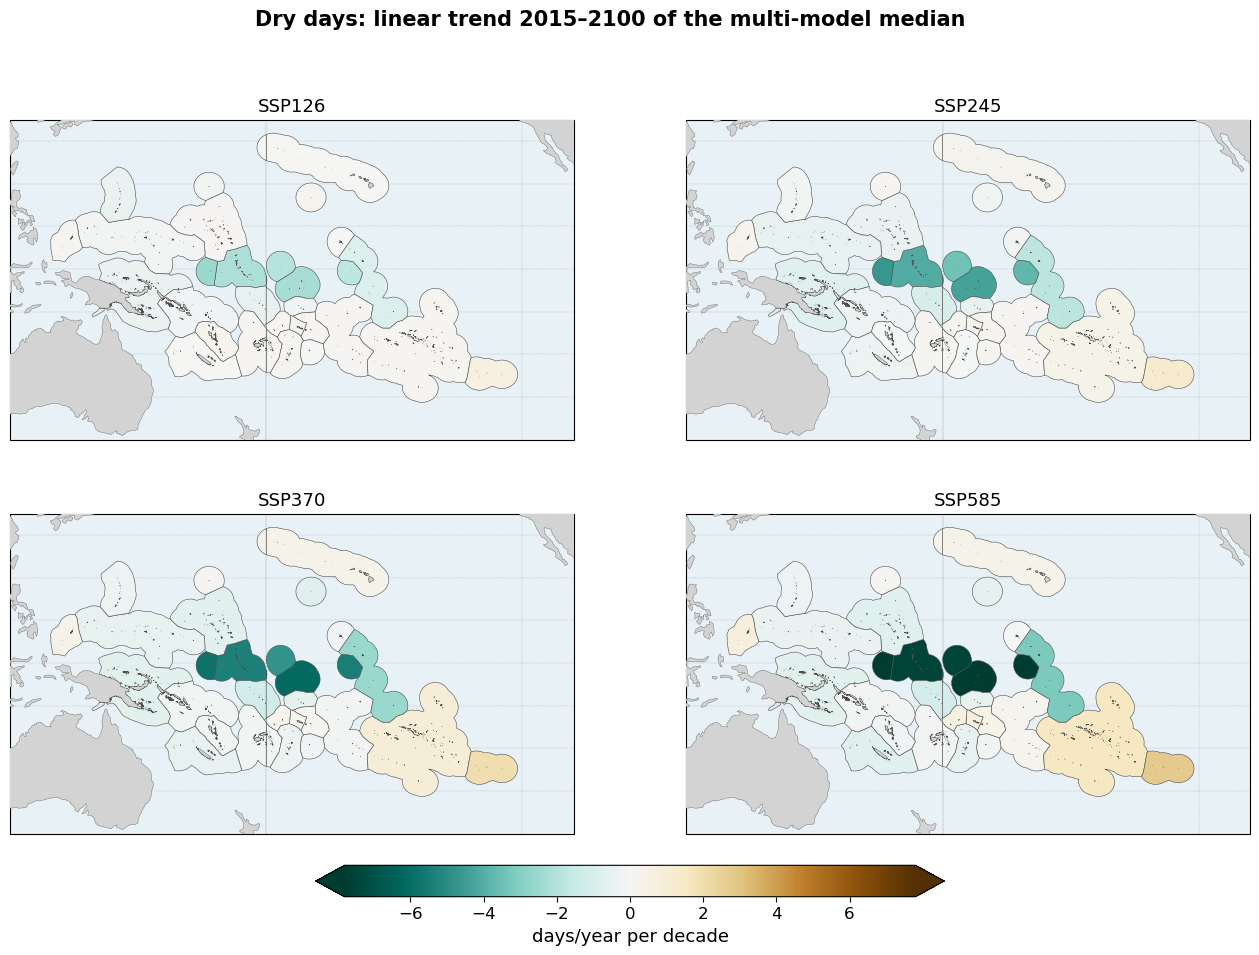

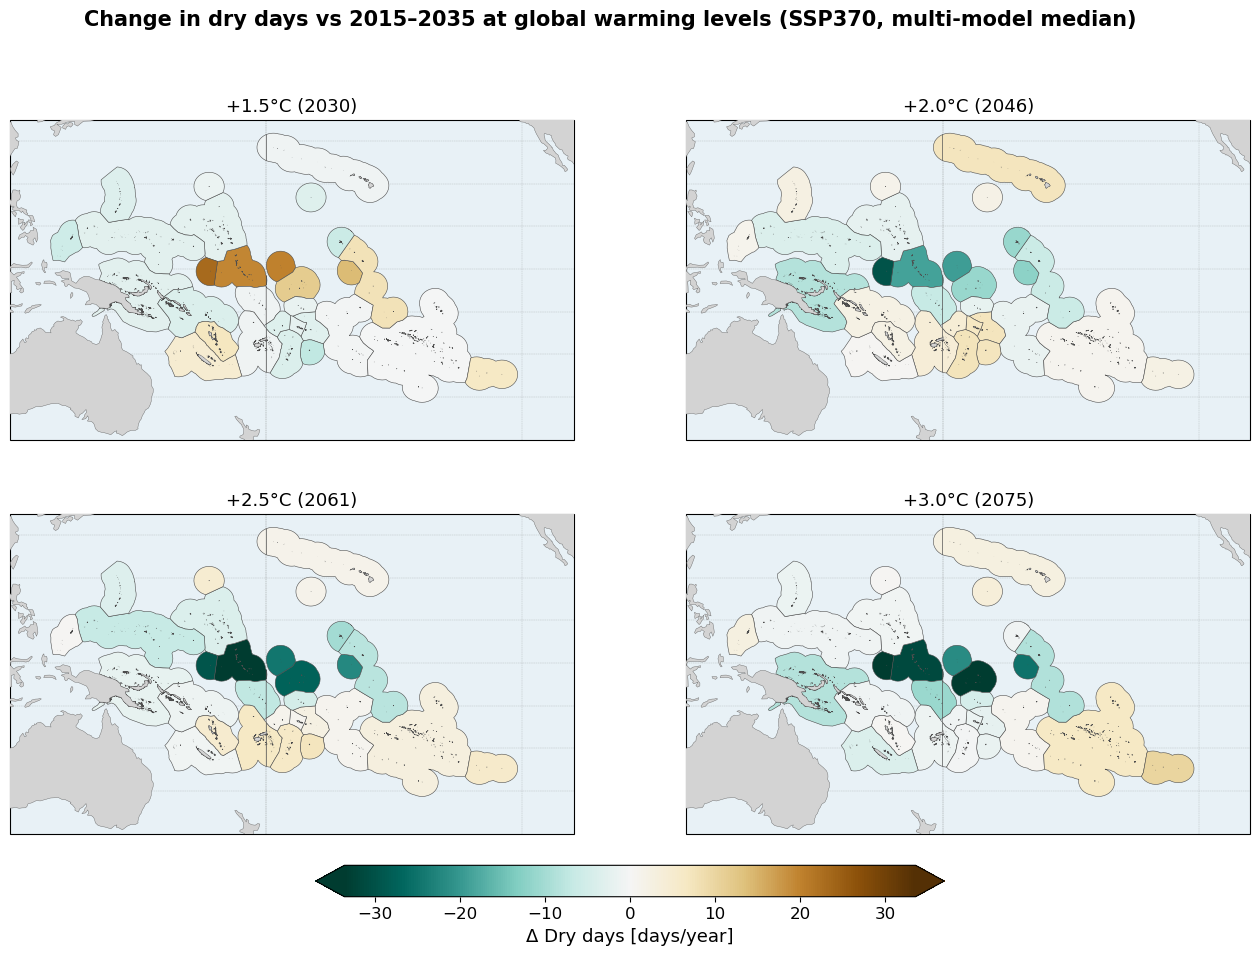

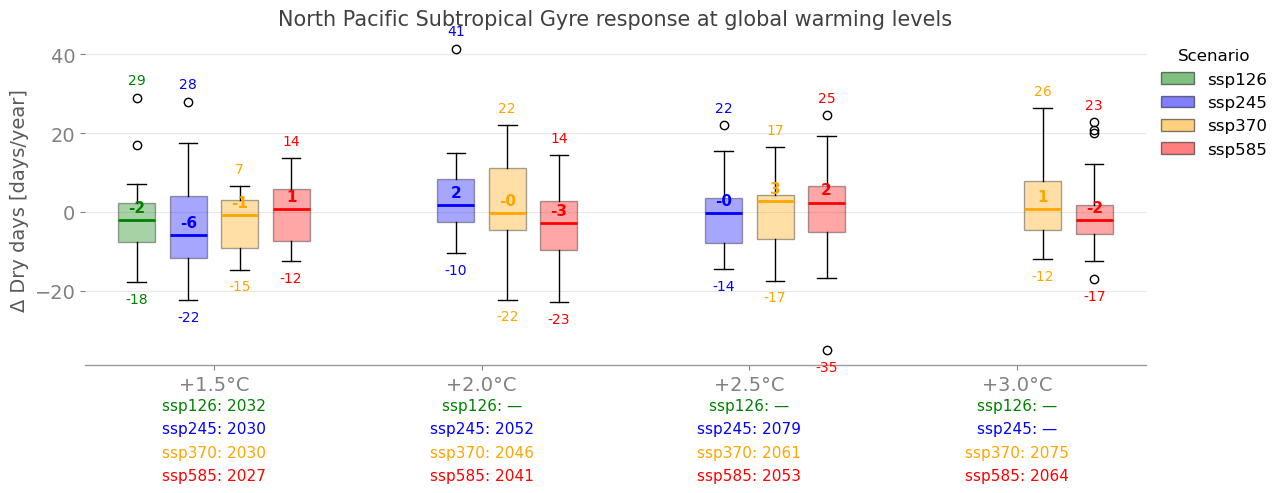

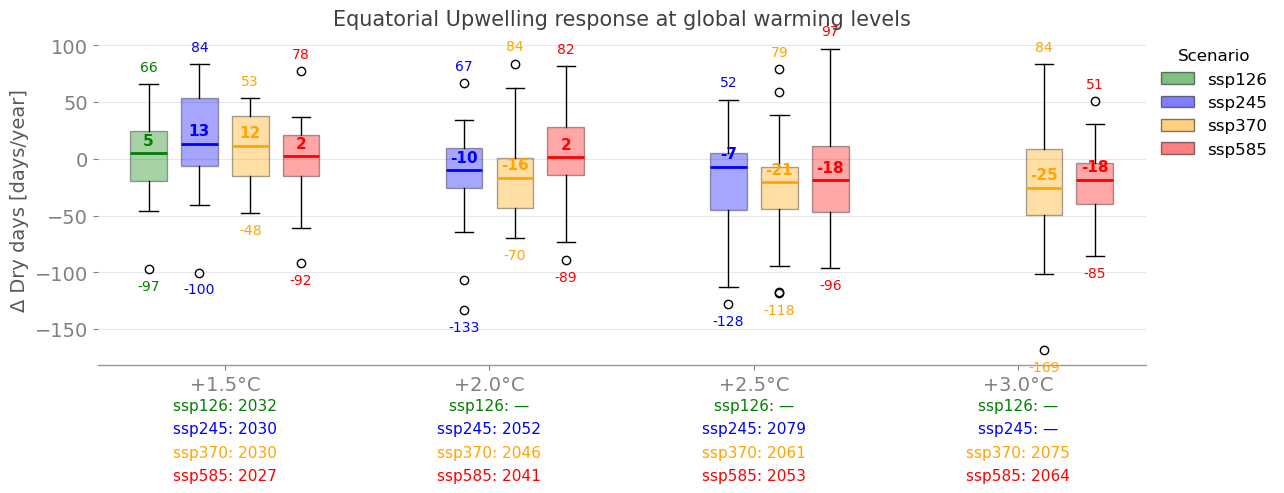

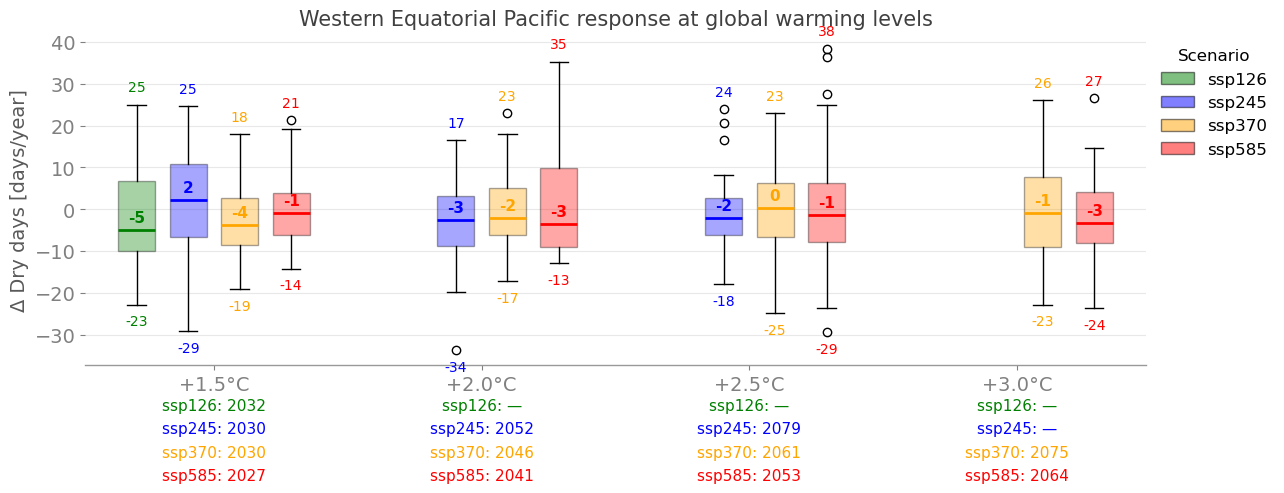

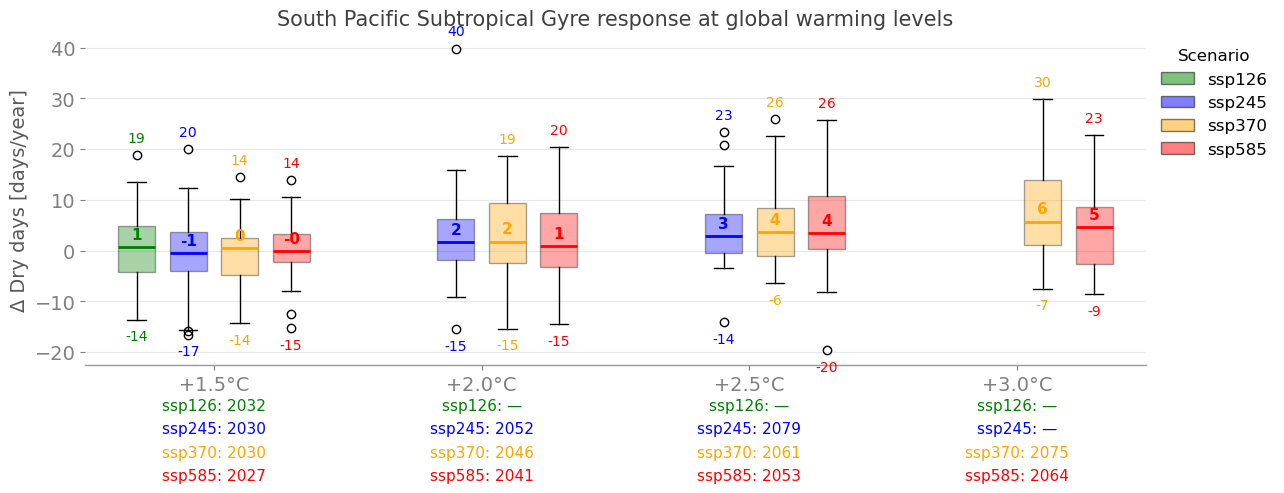

In [5]:
ds = reg.extract_regional_means("dry_days", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "dry_days", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
tables["regions"]

## Heavy-rainfall days

Annual number of heavy-rainfall days.

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP126,+1.5°C,2032,30,-0.2,-3.4,5.1,-8.8,7.1
1,North Pacific Subtropical Gyre,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,North Pacific Subtropical Gyre,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,North Pacific Subtropical Gyre,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,30,1.4,-3.9,4.7,-10.8,7.7
...,...,...,...,...,...,...,...,...,...,...
59,South Pacific Subtropical Gyre,SSP370,+3.0°C,2075,30,-0.2,-4.8,1.3,-7.9,2.6
60,South Pacific Subtropical Gyre,SSP585,+1.5°C,2027,30,-0.0,-1.5,2.2,-1.8,3.3
61,South Pacific Subtropical Gyre,SSP585,+2.0°C,2041,30,-0.2,-2.2,2.0,-4.3,3.0
62,South Pacific Subtropical Gyre,SSP585,+2.5°C,2053,30,0.4,-4.0,2.7,-5.5,3.8


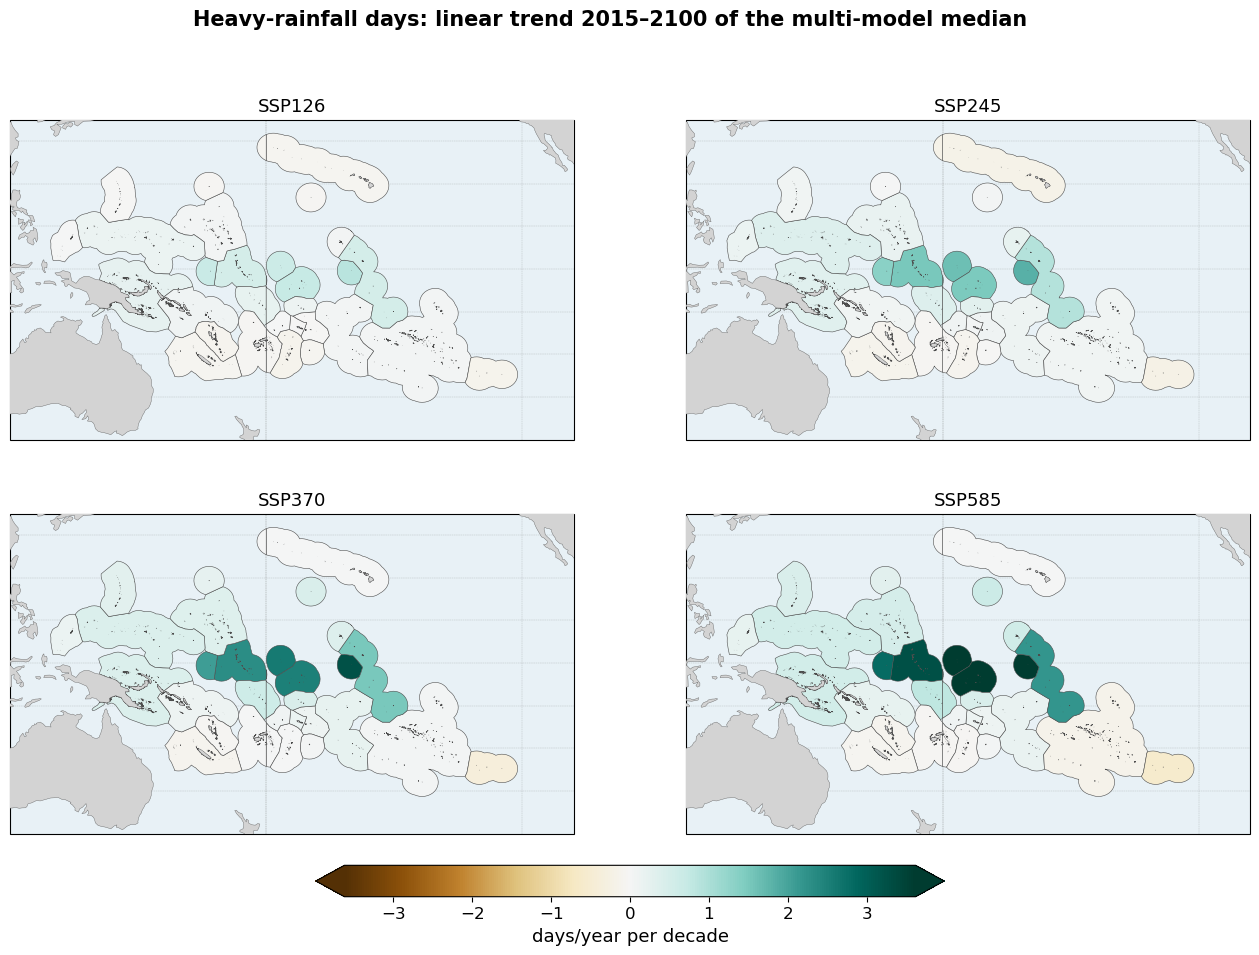

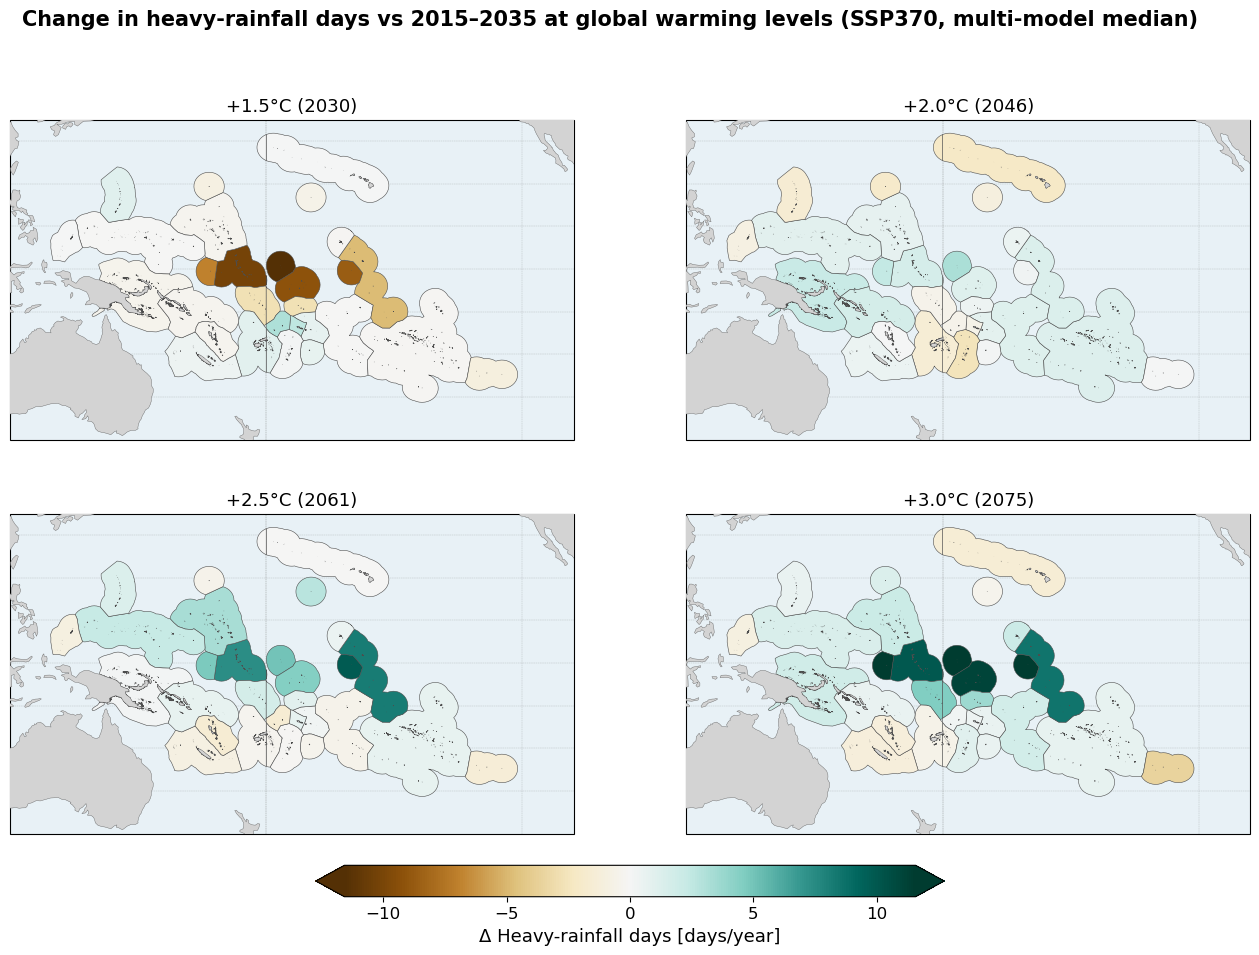

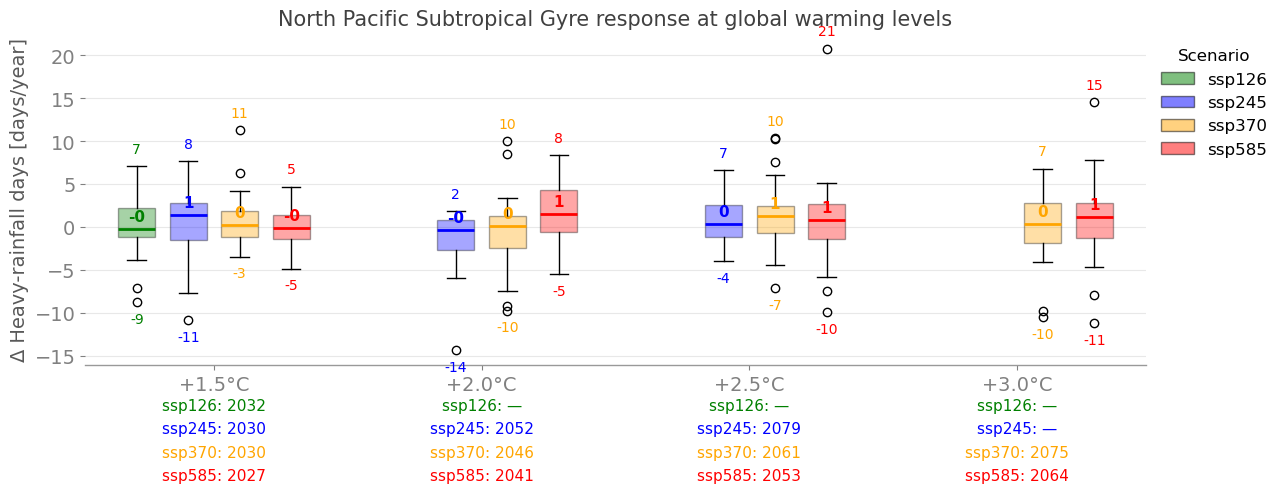

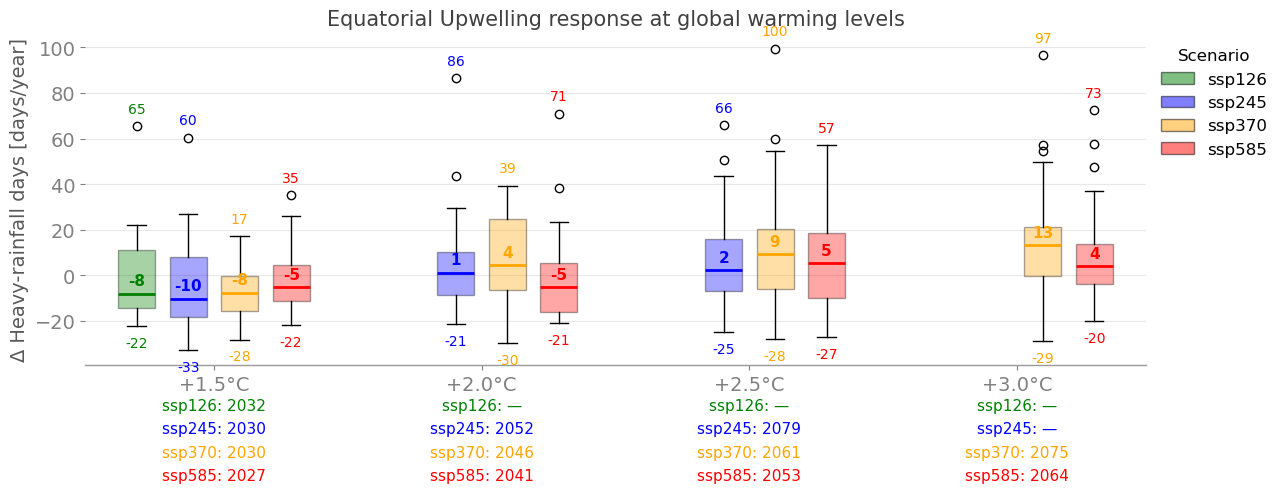

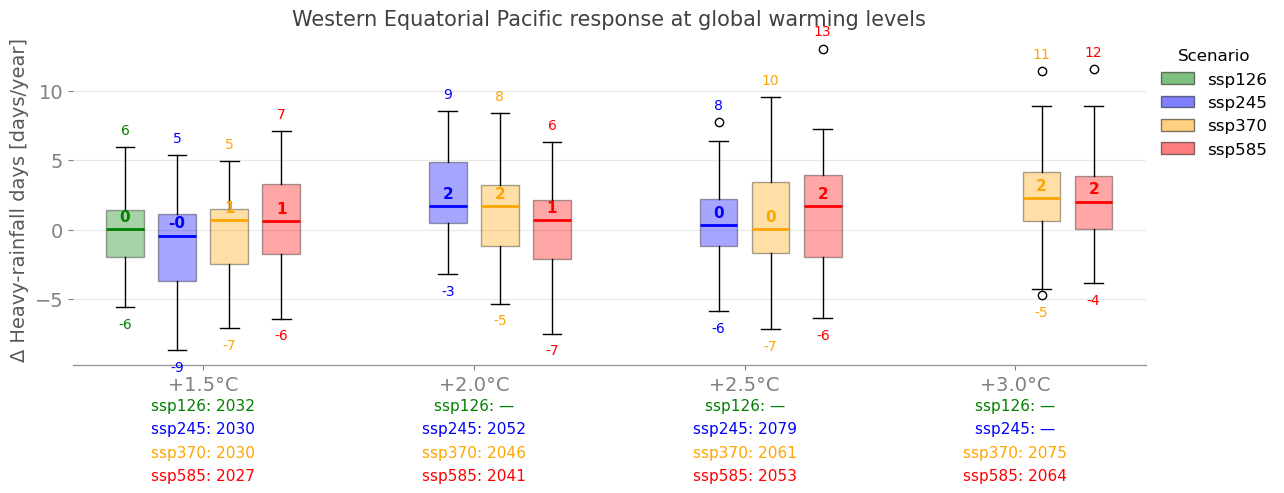

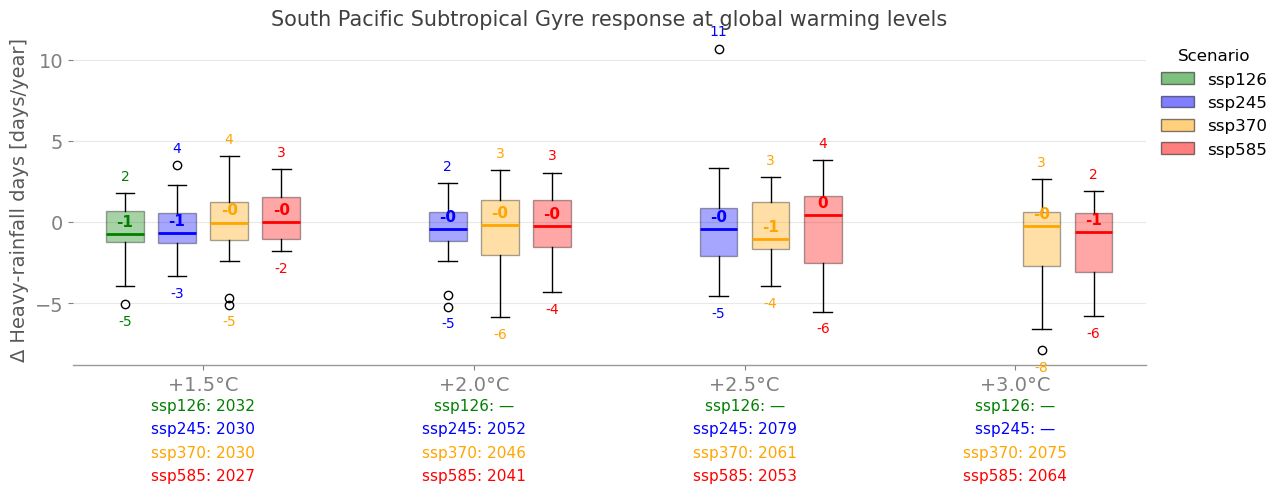

In [6]:
ds = reg.extract_regional_means("heavyraindays", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "heavyraindays", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
tables["regions"]

## Annual maximum daily rainfall

Annual maximum daily rainfall, change in %.

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP126,+1.5°C,2032,30,0.05,-12.80,16.59,-19.82,28.84
1,North Pacific Subtropical Gyre,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,North Pacific Subtropical Gyre,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,North Pacific Subtropical Gyre,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,30,1.59,-14.02,10.08,-31.97,24.03
...,...,...,...,...,...,...,...,...,...,...
59,South Pacific Subtropical Gyre,SSP370,+3.0°C,2075,30,10.55,-5.06,19.23,-13.24,36.55
60,South Pacific Subtropical Gyre,SSP585,+1.5°C,2027,30,0.08,-7.20,9.07,-9.98,18.39
61,South Pacific Subtropical Gyre,SSP585,+2.0°C,2041,30,3.61,-1.82,14.99,-12.59,31.47
62,South Pacific Subtropical Gyre,SSP585,+2.5°C,2053,30,8.16,-6.10,18.31,-13.04,21.62


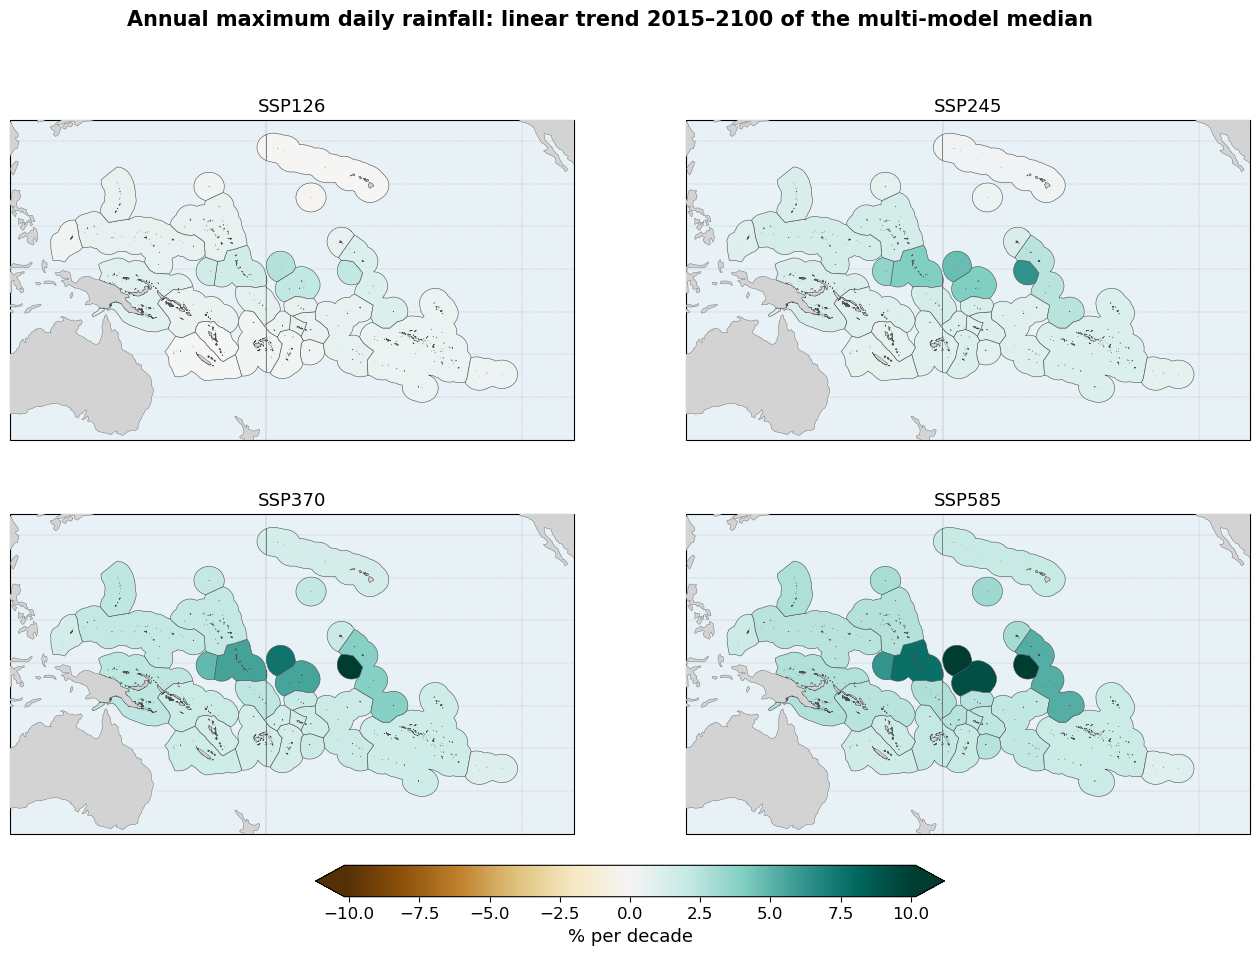

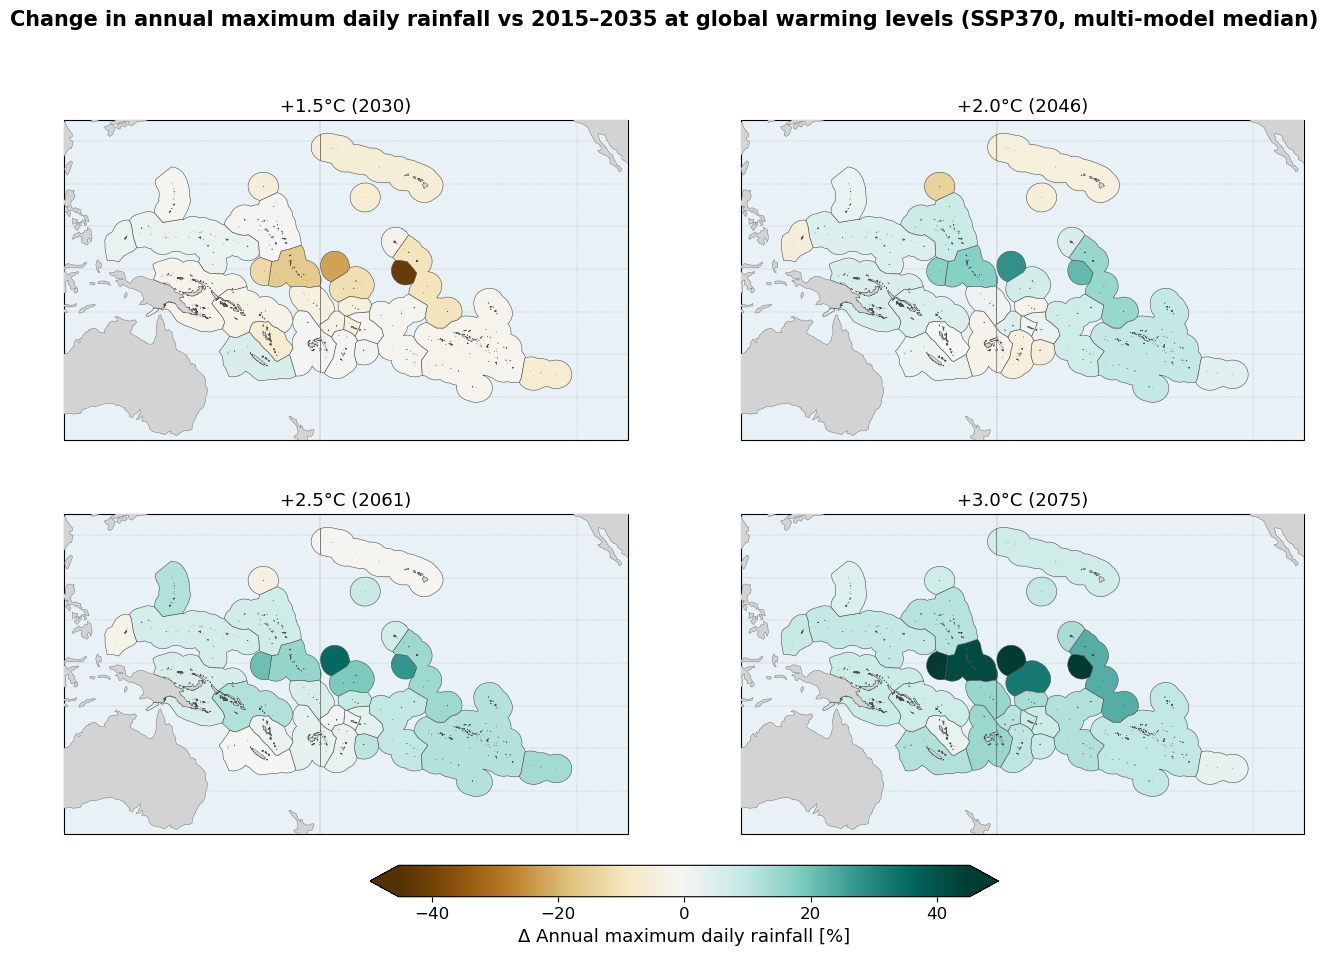

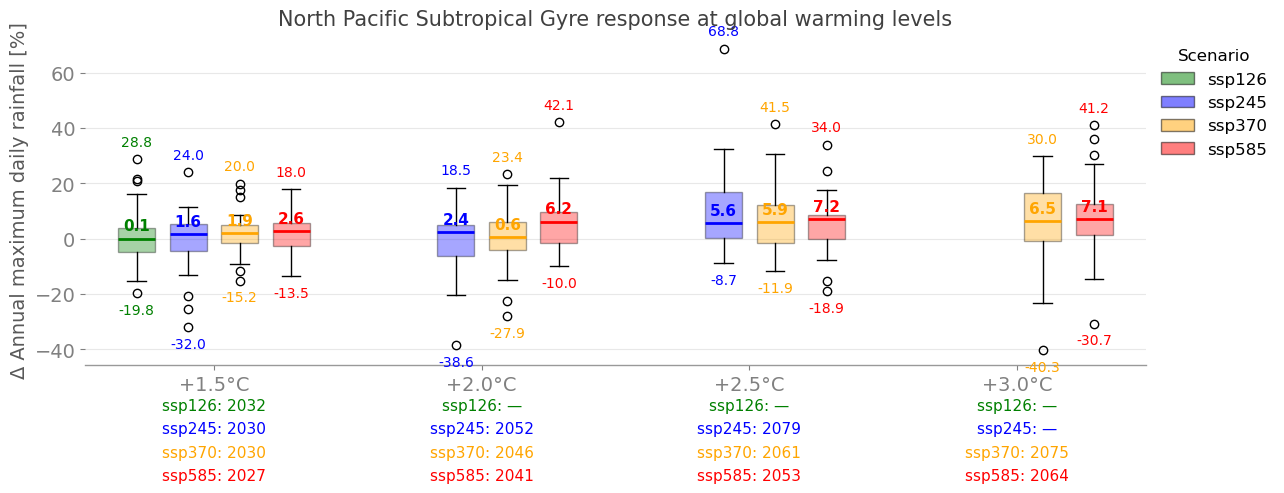

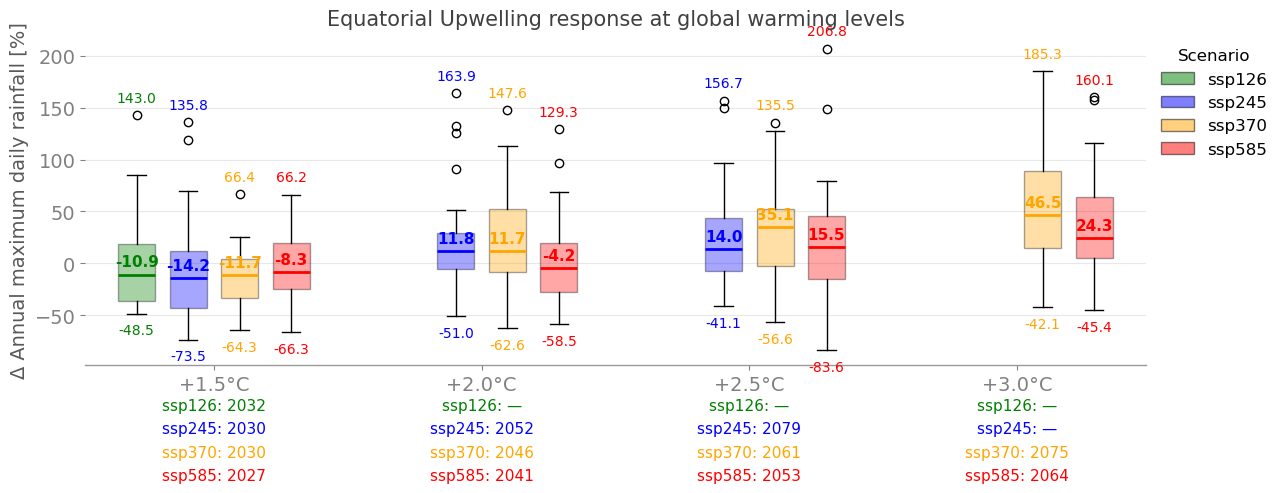

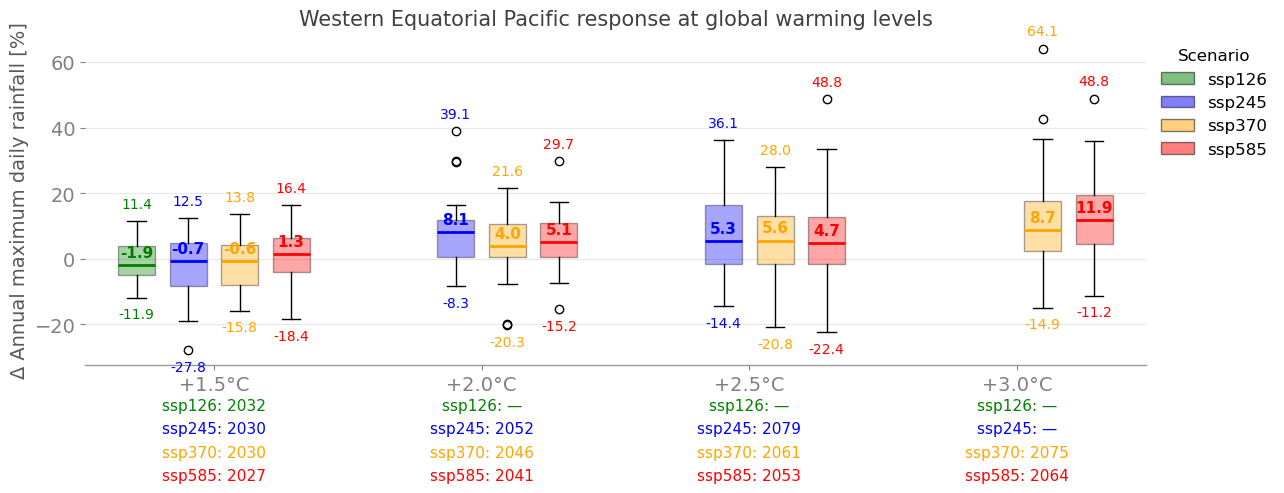

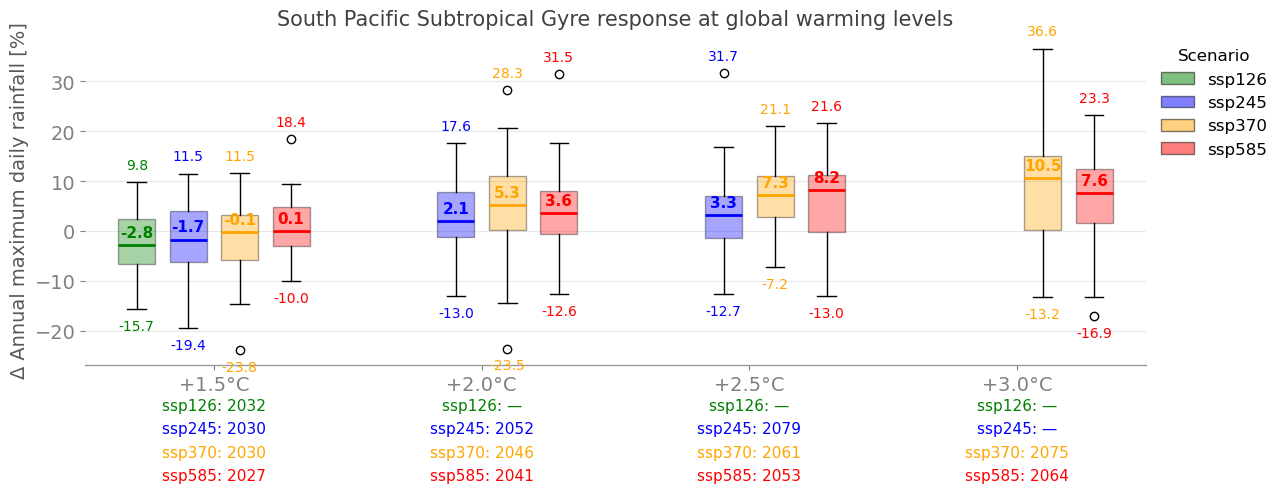

In [7]:
ds = reg.extract_regional_means("yearmax", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "yearmax", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
tables["regions"]